# Analyze Runtime and Memory Usage of PDX WGBS Read Sorting Algorithm Workflows

## 0. Imports and path assignments

In [1]:
import sys
sys.path.append("../helper")
from runtime_memory import *
from visualization import * 
from metrics import * 
from pathlib import Path
import os
import pandas as pd
from glob import glob
from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path.cwd().parent / "data" / "achinger-kawecka_2024"
pipelines_dir = data_dir / "pipelines"
fig_dir = Path.cwd() / "figures" / "runtime_memory"
os.makedirs(fig_dir, exist_ok = True)

hue_order=["Xengsort", "ICRG", "bamcmp"]

## 1. Alignment runtime & memory

In [3]:
pipeline_method_map = {
    "ICRG":       ["methylseq_bwameth_icrg"],
    "bamcmp":     ["methylseq_bwameth_GRCh38", "methylseq_bwameth_GRCm38"],
    #"XenofilteR": ["methylseq_bwameth_GRCh38", "methylseq_bwameth_GRCm382"],
    "Xengsort":   ["methylseq_bwameth_xengsort_GRCh38"],
}

In [5]:
alignments = process_nfcore_traces(data_dir, pipeline_method_map=pipeline_method_map)
alignments["realtime_h"] = alignments["realtime_s"] / 3600
alignments["peak_rss_gb"] = alignments["peak_rss_mb"] / 1000


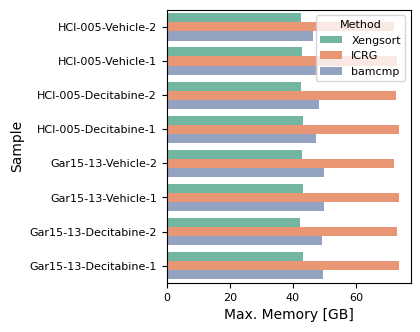

In [6]:
ax, pos = barplot_runmem(alignments, y="peak_rss_gb", x="sample", ylabel="Sample", xlabel="Max. Memory [GB]",
                hue="method", hue_order=hue_order, errorbar="sd",xtick_rotation = 0, horizontal = True,
                figsize=mm_to_inches((80, 90)), legend=True, save=True, reverse_order = True, fig_dir = fig_dir, file_name = "barplot_alignment_maxmemory.pdf")


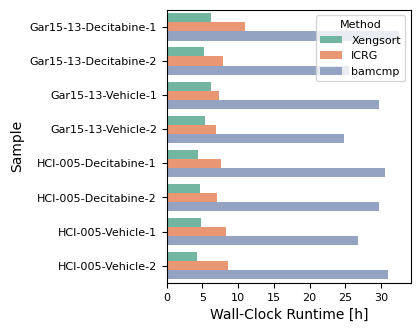

In [7]:

ax, pos = barplot_runmem(alignments, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue = "method", figsize=mm_to_inches((80, 90)), horizontal = True, legend=True, hue_order = hue_order, errorbar = "sd",
               save=True, xtick_rotation = 0, fig_dir=fig_dir, file_name="barplot_alignment_runtime.pdf")

## 2. Read sorting

In [8]:
log_dir = Path.cwd() / "logs"

In [9]:
xengsort = parse_lsf_logs(log_dir, method="xengsort", pattern="xengsort_*.out")

bamcmp   = parse_lsf_logs(log_dir, method="bamcmp",   pattern="bamcmp_*.out")

In [10]:
sortings = pd.concat([xengsort, bamcmp], ignore_index = True) 
sortings = transform_runmem(sortings)
sortings["method"] = sortings["method"].map(method_map)
sortings["stage"] = "sorting"

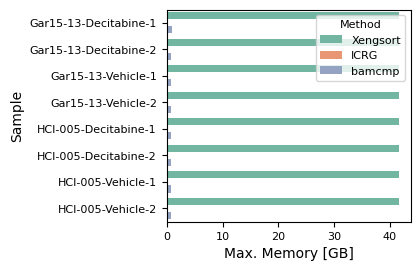

In [11]:
ax, pos = barplot_runmem(sortings, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel = "Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal=True, 
               figsize=mm_to_inches((80, 70)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_maxmemory.pdf")


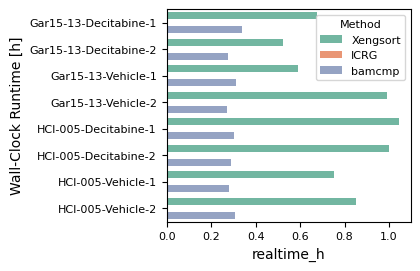

In [12]:
ax, pos = barplot_runmem(sortings, y="realtime_h", x="sample", ylabel="Wall-Clock Runtime [h]",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((80, 70)), legend=True, save=True, fig_dir = fig_dir, file_name = "barplot_sortings_runtime.pdf")


## 3. Alignment and Sorting

In [13]:

concat = pd.concat([alignments, sortings], ignore_index = True)

In [14]:
final_df = (
    concat
    .groupby(["sample", "method"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_df["realtime_h"]  = final_df["realtime_s"] / 3600
final_df["peak_rss_gb"] = final_df["peak_rss_mb"] / 1000


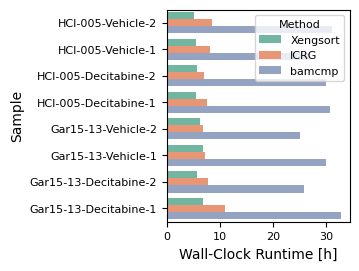

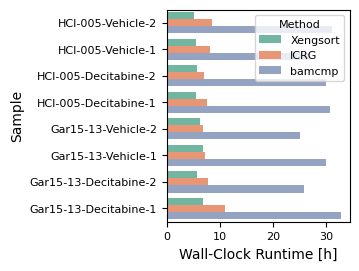

In [15]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_df, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel = "Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, reverse_order = True,
                figsize=mm_to_inches((60, 70)), legend=True, save=True, fig_dir = fig_dir, file_name = f"barplot_final_runtime.{suffix}")


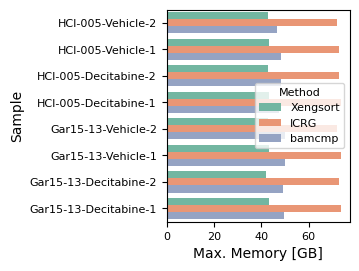

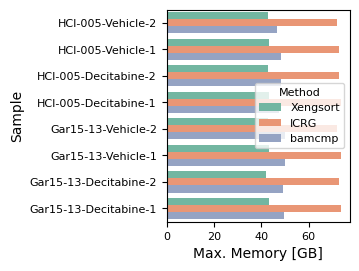

In [16]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_df, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, reverse_order = True,
               figsize=mm_to_inches((60, 70)), legend=True, save=True, fig_dir = fig_dir, file_name = f"barplot_final_maxmemory.{suffix}")


In [17]:
summary_df = (
    final_df
    .groupby("method", as_index=False)
    .agg(realtime_s=("realtime_s", "mean"), peak_rss_mb=("peak_rss_mb", "mean"))
)
summary_df["realtime_h"]  = summary_df["realtime_s"] / 3600
summary_df["peak_rss_gb"] = summary_df["peak_rss_mb"] / 1000


## Save dataframes

In [24]:
sortings.to_csv(data_dir / "sortings.csv")
alignments.to_csv(data_dir / "alignments.csv")
final_df.to_csv(data_dir / "final.csv")
summary_df.to_csv(data_dir /"summary.csv")